<a href="https://colab.research.google.com/github/akshaya19200/Bilstm/blob/main/Amazon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


Pandas version: 2.2.3
TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload your Amazon dataset CSV file.")

file_path = csv_files[0]

print("Uploaded file:", file_path)


Saving amazon.csv to amazon.csv
Uploaded file: amazon.csv


In [ ]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 1465
Number of columns: 16


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [ ]:

print("Column names in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

print("\nTotal columns:", len(df.columns))


Column names in the dataset:

1. product_id
2. product_name
3. category
4. discounted_price
5. actual_price
6. discount_percentage
7. rating
8. rating_count
9. about_product
10. user_id
11. user_name
12. review_id
13. review_title
14. review_content
15. img_link
16. product_link

Total columns: 16


In [ ]:

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

print(df.columns.tolist())


['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


In [ ]:

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nData types:")
display(df.dtypes)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null

,0
rating_count,2
product_id,0
category,0
product_name,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
about_product,0
user_id,0



Data types:


,0
product_id,object
product_name,object
category,object
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object
about_product,object
user_id,object


In [ ]:

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)


Duplicate rows: 0
Dataset shape after removing duplicates: (1465, 16)


In [ ]:


df["rating"] = pd.to_numeric(
    df["rating"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing or invalid ratings:", df["rating"].isna().sum())
print("\nRating statistics:")
display(df["rating"].describe())

print("\nUnique ratings:")
print(sorted(df["rating"].dropna().unique()))


Missing or invalid ratings: 1

Rating statistics:


,rating
count,1464.000000
mean,4.096585
std,0.291674
min,2.000000
25%,4.000000
50%,4.100000
75%,4.300000
max,5.000000



Unique ratings:
[np.float64(2.0), np.float64(2.3), np.float64(2.6), np.float64(2.8), np.float64(2.9), np.float64(3.0), np.float64(3.1), np.float64(3.2), np.float64(3.3), np.float64(3.4), np.float64(3.5), np.float64(3.6), np.float64(3.7), np.float64(3.8), np.float64(3.9), np.float64(4.0), np.float64(4.1), np.float64(4.2), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(4.7), np.float64(4.8), np.float64(5.0)]


In [ ]:


df = df.dropna(subset=["rating"]).copy()

df = df[df["rating"].between(1, 5)].copy()

print("Rows remaining:", len(df))
print("Rating range:", df["rating"].min(), "to", df["rating"].max())


Rows remaining: 1464
Rating range: 2.0 to 5.0


In [ ]:

numeric_columns = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count"
]

def convert_to_numeric(series):
    series = (
        series.astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    return pd.to_numeric(series, errors="coerce")

for col in numeric_columns:
    df[col] = convert_to_numeric(df[col])

print("Numeric conversion completed.")
display(df[numeric_columns].head())

print("\nMissing numeric values:")
display(df[numeric_columns].isnull().sum())


Numeric conversion completed.


,discounted_price,actual_price,discount_percentage,rating_count
0,399.0,1099.0,64,24269.0
1,199.0,349.0,43,43994.0
2,199.0,1899.0,90,7928.0
3,329.0,699.0,53,94363.0
4,154.0,399.0,61,16905.0



Missing numeric values:


,0
discounted_price,0
actual_price,0
discount_percentage,0
rating_count,2


In [ ]:

text_columns = [
    "product_name",
    "category",
    "about_product",
    "review_title",
    "review_content"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

print("Missing text values handled.")

display(df[text_columns].head())


Missing text values handled.


,product_name,category,about_product,review_title,review_content
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,High Compatibility : Compatible With iPhone 12...,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,"Compatible with all Type C enabled devices, be...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...
2,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,【 Fast Charger& Data Sync】-With built-in safet...,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a..."
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,The boAt Deuce USB 300 2 in 1 cable is compati...,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou..."
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th..."


In [ ]:
df["combined_text"] = (
    "Product: " + df["product_name"] +
    " Description: " + df["about_product"] +
    " Review title: " + df["review_title"] +
    " Review content: " + df["review_content"]
).str.strip()

print("Combined text created.")
display(df[["combined_text", "rating"]].head(3))


Combined text created.


,combined_text,rating
0,Product: Wayona Nylon Braided USB to Lightning...,4.2
1,Product: Ambrane Unbreakable 60W / 3A Fast Cha...,4.0
2,Product: Sounce Fast Phone Charging Cable & Da...,3.9


In [ ]:
TEXT_COL = "combined_text"

CAT_COLS = ["category"]

NUM_COLS = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count"
]

TARGET_COL = "rating"

# Remove rows without meaningful text
df = df[df["combined_text"].str.strip() != ""].copy()

X_text = df[TEXT_COL].astype(str)
X_cat = df[CAT_COLS].copy()
X_num = df[NUM_COLS].copy()
y = df[TARGET_COL].astype("float32")

print("Text features:", X_text.shape)
print("Categorical features:", X_cat.shape)
print("Numeric features:", X_num.shape)
print("Target:", y.shape)


Text features: (1464,)
Categorical features: (1464, 1)
Numeric features: (1464, 4)
Target: (1464,)


In [ ]:

# Cell 14: Split the dataset

indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

X_text_train = X_text.iloc[train_idx]
X_text_val = X_text.iloc[val_idx]
X_text_test = X_text.iloc[test_idx]

X_cat_train = X_cat.iloc[train_idx]
X_cat_val = X_cat.iloc[val_idx]
X_cat_test = X_cat.iloc[test_idx]

X_num_train = X_num.iloc[train_idx]
X_num_val = X_num.iloc[val_idx]
X_num_test = X_num.iloc[test_idx]

y_train = y.iloc[train_idx].to_numpy()
y_val = y.iloc[val_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Testing records:", len(test_idx))


Training records: 1024
Validation records: 220
Testing records: 220


In [ ]:

num_imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_num_train_imp = num_imputer.fit_transform(X_num_train)
X_num_val_imp = num_imputer.transform(X_num_val)
X_num_test_imp = num_imputer.transform(X_num_test)

X_num_train_scaled = scaler.fit_transform(
    X_num_train_imp
).astype("float32")

X_num_val_scaled = scaler.transform(
    X_num_val_imp
).astype("float32")

X_num_test_scaled = scaler.transform(
    X_num_test_imp
).astype("float32")

print("Numeric preprocessing completed.")
print("Training numeric shape:", X_num_train_scaled.shape)


Numeric preprocessing completed.
Training numeric shape: (1024, 4)


In [ ]:

# Cell 16: One-hot encode categories

try:
    category_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    category_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

X_cat_train_encoded = category_encoder.fit_transform(
    X_cat_train.fillna("Unknown").astype(str)
).astype("float32")

X_cat_val_encoded = category_encoder.transform(
    X_cat_val.fillna("Unknown").astype(str)
).astype("float32")

X_cat_test_encoded = category_encoder.transform(
    X_cat_test.fillna("Unknown").astype(str)
).astype("float32")

X_struct_train = np.concatenate(
    [X_num_train_scaled, X_cat_train_encoded],
    axis=1
).astype("float32")

X_struct_val = np.concatenate(
    [X_num_val_scaled, X_cat_val_encoded],
    axis=1
).astype("float32")

X_struct_test = np.concatenate(
    [X_num_test_scaled, X_cat_test_encoded],
    axis=1
).astype("float32")

print("Combined structured features prepared.")
print("Training structured shape:", X_struct_train.shape)
print("Validation structured shape:", X_struct_val.shape)
print("Testing structured shape:", X_struct_test.shape)


Combined structured features prepared.
Training structured shape: (1024, 190)
Validation structured shape: (220, 190)
Testing structured shape: (220, 190)


In [ ]:

MAX_TOKENS = 10000
SEQUENCE_LENGTH = 150

text_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH
)

text_dataset = tf.data.Dataset.from_tensor_slices(
    X_text_train.to_numpy()
).batch(32)

text_vectorizer.adapt(text_dataset)

vocabulary_size = len(text_vectorizer.get_vocabulary())

print("Vocabulary size:", vocabulary_size)

example = tf.constant([
    "This product is excellent and works very well"
])

print("Encoded sequence:")
print(text_vectorizer(example).numpy())


Vocabulary size: 10000
Encoded sequence:
[[ 15  12   5 322   3  94  24  76   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0]]


In [ ]:

# Cell 18: Build hybrid model

text_input = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="review_text"
)

feature_input = tf.keras.Input(
    shape=(X_struct_train.shape[1],),
    dtype=tf.float32,
    name="product_features"
)

# Text branch
x = text_vectorizer(text_input)

x = tf.keras.layers.Embedding(
    input_dim=vocabulary_size,
    output_dim=64,
    mask_zero=True
)(x)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(32)
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

# Structured-feature branch
p = tf.keras.layers.Dense(
    32,
    activation="relu"
)(feature_input)

p = tf.keras.layers.Dropout(0.2)(p)

# Merge both branches
combined = tf.keras.layers.Concatenate()([x, p])

combined = tf.keras.layers.Dense(
    32,
    activation="relu"
)(combined)

combined = tf.keras.layers.Dropout(0.3)(combined)

# Rating prediction
output = tf.keras.layers.Dense(
    1,
    activation="linear",
    name="predicted_rating"
)(combined)

model = tf.keras.Model(
    inputs=[text_input, feature_input],
    outputs=output
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_text         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 150)       │          0 │ review_text[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_features    │ (None, 190)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     24,832 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      6,112 │ product_features… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      3,104 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predicted_rating    │ (None, 1)         │         33 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 674,081 (2.57 MB)

 Trainable params: 674,081 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.Huber(delta=1.0),
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

print("Model compiled successfully.")


Model compiled successfully.


In [ ]:

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    {
        "review_text": X_text_train.to_numpy(),
        "product_features": X_struct_train
    },
    y_train,
    validation_data=(
        {
            "review_text": X_text_val.to_numpy(),
            "product_features": X_struct_val
        },
        y_val
    ),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 38s 281ms/step - loss: 1.4254 - mae: 1.8558 - rmse: 2.3397 - val_loss: 0.0453 - val_mae: 0.2494 - val_rmse: 0.3011 - learning_rate: 0.0010
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 182ms/step - loss: 0.3833 - mae: 0.7498 - rmse: 0.9309 - val_loss: 0.0555 - val_mae: 0.2834 - val_rmse: 0.3332 - learning_rate: 0.0010
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 186ms/step - loss: 0.3508 - mae: 0.7179 - rmse: 0.8804 - val_loss: 0.0482 - val_mae: 0.2393 - val_rmse: 0.3105 - learning_rate: 0.0010
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 159ms/step - loss: 0.3016 - mae: 0.6520 - rmse: 0.8117 - val_loss: 0.0422 - val_mae: 0.2449 - val_rmse: 0.2905 - learning_rate: 0.0010
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 185ms/step - loss: 0.3074 - mae: 0.6606 - rmse: 0.8238 - val_loss: 0.0798 - val_mae: 0.3421 - val_rmse: 0.3997 - learning_rate: 0.0010
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 21s 195ms/step - loss: 0.2789 - mae: 0.6156 - rmse: 0.7822 - val_loss: 0.0650

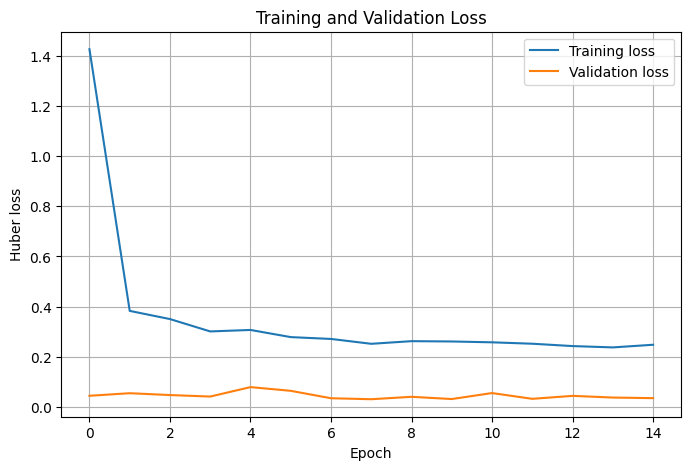

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Huber loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

test_predictions = model.predict(
    {
        "review_text": X_text_test.to_numpy(),
        "product_features": X_struct_test
    },
    verbose=0
).ravel()

# Restrict predictions to the valid rating range
test_predictions = np.clip(test_predictions, 1, 5)

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))


MAE: 0.2089
RMSE: 0.2997
R²: 0.0978


,Actual Rating,Predicted Rating,Absolute Error
0,3.5,3.767,0.267
1,4.0,3.981,0.019
2,4.0,3.990,0.010
3,4.3,4.304,0.004
4,4.1,4.221,0.121
5,4.0,3.945,0.055
6,4.2,3.917,0.283
7,4.1,4.148,0.048
8,4.4,4.052,0.348
9,4.3,4.302,0.002


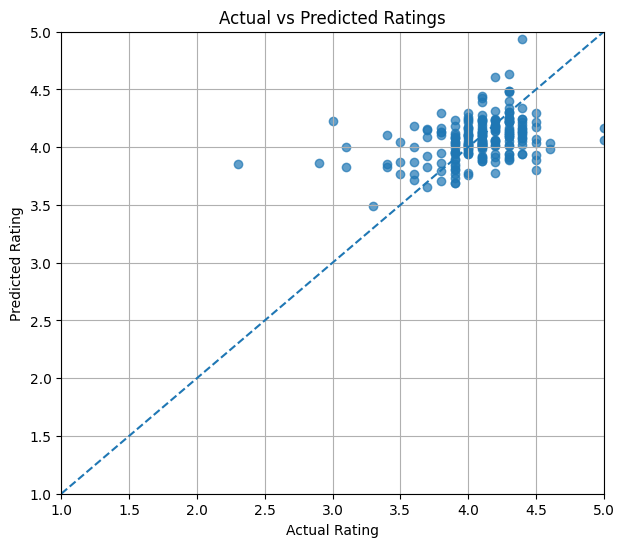

In [ ]:
comparison = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": test_predictions,
    "Absolute Error": np.abs(y_test - test_predictions)
})

display(comparison.head(15).round(3))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_predictions, alpha=0.7)
plt.plot([1, 5], [1, 5], linestyle="--")

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.grid(True)
plt.show()


In [ ]:

def predict_rating(review_text, category, discounted_price,
                   actual_price, discount_percentage, rating_count):

    text_input_array = np.array([str(review_text)], dtype=str)

    numeric_input = pd.DataFrame([{
        "discounted_price": discounted_price,
        "actual_price": actual_price,
        "discount_percentage": discount_percentage,
        "rating_count": rating_count
    }], columns=NUM_COLS)

    for col in NUM_COLS:
        numeric_input[col] = convert_to_numeric(numeric_input[col])

    numeric_imputed = num_imputer.transform(numeric_input)
    numeric_scaled = scaler.transform(numeric_imputed)

    category_input = pd.DataFrame({
        "category": [str(category)]
    })

    category_encoded = category_encoder.transform(category_input)

    structured_input = np.concatenate(
        [numeric_scaled, category_encoded], axis=1
    ).astype("float32")

    prediction = model.predict(
        {
            "review_text": text_input_array,
            "product_features": structured_input
        },
        verbose=0
    )[0, 0]

    prediction = float(np.clip(prediction, 1, 5))

    print("Predicted product rating:", round(prediction, 2), "/ 5 stars")

    return prediction
    predict_rating(
    review_text="The product is very good and works perfectly. Quality is excellent.",
    category="Electronics",
    discounted_price=999,
    actual_price=1499,
    discount_percentage=33,
    rating_count=250
)


In [ ]:
print("Model:", "model" in globals())
print("NUM_COLS:", "NUM_COLS" in globals())
print("Imputer:", "num_imputer" in globals())
print("Scaler:", "scaler" in globals())
print("Category encoder:", "category_encoder" in globals())
print("Numeric converter:", "convert_to_numeric" in globals())

Model: True
NUM_COLS: True
Imputer: True
Scaler: True
Category encoder: True
Numeric converter: True


In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf

def predict_rating(review_text, category, discounted_price,
                   actual_price, discount_percentage, rating_count):

    # 1. Prepare review text
    text_input_array = tf.constant(
        [str(review_text)], dtype=tf.string
    )

    # 2. Prepare numerical features
    numeric_input = pd.DataFrame([{
        "discounted_price": discounted_price,
        "actual_price": actual_price,
        "discount_percentage": discount_percentage,
        "rating_count": rating_count
    }], columns=NUM_COLS)

    for col in NUM_COLS:
        numeric_input[col] = convert_to_numeric(numeric_input[col])

    # 3. Handle missing values and scale numerical data
    numeric_imputed = num_imputer.transform(numeric_input)
    numeric_scaled = scaler.transform(numeric_imputed)

    # 4. Encode product category
    category_input = pd.DataFrame({
        "category": [str(category)]
    })

    category_encoded = category_encoder.transform(category_input)

    # 5. Combine product features
    structured_input = np.concatenate(
        [numeric_scaled, category_encoded], axis=1
    ).astype("float32")

    # 6. Predict rating
    prediction = model.predict(
        {
            "review_text": text_input_array,
            "product_features": structured_input
        },
        verbose=0
    )[0, 0]

    # 7. Keep rating between 1 and 5
    prediction = float(np.clip(prediction, 1, 5))

    print("Predicted Product Rating:", round(prediction, 2), "/ 5 Stars")

    return prediction


# 8. Test the prediction function
predict_rating(
    review_text="The product is very good and works perfectly. Quality is excellent.",
    category="Electronics",
    discounted_price=999,
    actual_price=1499,
    discount_percentage=33,
    rating_count=250
)


Predicted Product Rating: 2.99 / 5 Stars


2.9859254360198975

In [ ]:
print("X_text exists:", "X_text" in globals())
print("test_idx exists:", "test_idx" in globals())
print("X_structured exists:", "X_structured" in globals())
print("y_test exists:", "y_test" in globals())
print("model exists:", "model" in globals())

X_text exists: True
test_idx exists: True
X_structured exists: False
y_test exists: True
model exists: True


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Check available structured feature variable names
print("Available feature variables:")
for name in ["numeric_scaled", "category_encoded", "X_train_structured",
             "X_test_structured", "X_train", "X_test"]:
    print(name, "exists:", name in globals())

Available feature variables:
numeric_scaled exists: False
category_encoded exists: False
X_train_structured exists: False
X_test_structured exists: False
X_train exists: False
X_test exists: False


In [ ]:

# Prepare structured features for the test rows

numeric_data = df[NUM_COLS].copy()

for col in NUM_COLS:
    numeric_data[col] = convert_to_numeric(numeric_data[col])

numeric_imputed_all = num_imputer.transform(numeric_data)
numeric_scaled_all = scaler.transform(numeric_imputed_all)

category_data = df[["category"]].fillna("Unknown").astype(str)
category_encoded_all = category_encoder.transform(category_data)

X_structured_all = np.concatenate(
    [numeric_scaled_all, category_encoded_all], axis=1
).astype("float32")

X_structured_test = X_structured_all[test_idx]

print("Test structured features shape:", X_structured_test.shape)
print("Test rows:", len(test_idx))


Test structured features shape: (220, 190)
Test rows: 220


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

text_test = X_text.iloc[test_idx].astype(str).to_numpy()

y_pred = model.predict(
    {
        "review_text": text_test,
        "product_features": X_structured_test
    },
    verbose=0
).flatten()

y_pred = np.clip(y_pred, 1, 5)

# Get the true ratings for the same test rows
y_actual = df["rating"].iloc[test_idx].to_numpy(dtype=float)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))


Model Evaluation Results
------------------------
MAE: 0.209
RMSE: 0.3
R2 Score: 0.098
